# Model B: MobileNetV2 (Transfer Learning)

Binary classification of real and AI-generated images using a pretrained MobileNetV2 (ImageNet).

Training environment: Google Colab (use a GPU runtime)
Dataset: Defactify Image Dataset
Framework: TensorFlow / Keras

Experiment plan:
1. Verify the shared split manifests (no caption-group leakage).
2. Tuning on a small subset (head learning rate and dropout).
3. Stage 1: frozen backbone (feature extraction) + new classification head.
4. Stage 2: fine-tune the last layers of the backbone with a low learning rate.
5. Pick the best model by **validation loss** and save it to `artifacts/models/`.


In [2]:
!pip -q install datasets huggingface_hub

In [3]:
import os
import json
import shutil
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras

if not hasattr(keras, "KerasTensor"):
    from keras.src.backend import KerasTensor
    keras.KerasTensor = KerasTensor

from pathlib import Path
from PIL import Image as PILImage
from datasets import load_dataset
from huggingface_hub import HfApi
from tensorflow.keras import layers, models

In [4]:
import keras
from keras.src.backend import KerasTensor
keras.KerasTensor = KerasTensor

## Repository Setup

Clone (or update) the team repository so this notebook uses exactly the same `train.csv`, `validation.csv`, and `test.csv` as Model A.

In [5]:
REPO_URL = "https://github.com/Michaelatj/AI-Generated-Image-Classification-using-CNN.git"
REPO_DIR = Path("/content/AI-Generated-Image-Classification-using-CNN")

if not REPO_DIR.exists():
    subprocess.run(["git", "clone", REPO_URL, str(REPO_DIR)], check=True)

os.chdir(REPO_DIR)

status = subprocess.check_output(["git", "status", "--porcelain"], text=True)
if status.strip():
    raise RuntimeError("Repository contains local changes. Check git status before syncing.")

subprocess.run(["git", "pull", "--rebase", "origin", "main"], check=True)

print(subprocess.check_output(["git", "log", "--oneline", "-n", "8"], text=True))

ARTIFACT_DIR = REPO_DIR / "artifacts"
SPLIT_DIR = ARTIFACT_DIR / "splits"
CONFIG_DIR = ARTIFACT_DIR / "configs"
MODEL_DIR = ARTIFACT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Splits:", sorted(p.name for p in SPLIT_DIR.glob("*")))
print("Configs:", sorted(p.name for p in CONFIG_DIR.glob("*")))

bb5ef7c Created using Colab
6360592 Train and save Custom CNN model
b6f54d1 Created using Colab
eb22031 updated eda notebook
7352308 Created using Colab
92203ec Add Custom CNN integration test
5e46b05 Add Custom CNN integration test model
0dfbb1f Update .gitignore

Splits: ['test.csv', 'train.csv', 'validation.csv']
Configs: ['dataset_manifest.json', 'label_mapping.json', 'preprocessing_config.json']


In [6]:
SEED = 42
tf.keras.utils.set_random_seed(SEED)

gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as error:
        print(error)

print("TensorFlow:", tf.__version__)
print("Available GPU:", gpus)
if not gpus:
    print("WARNING: no GPU found. Runtime > Change runtime type > T4 GPU.")

total, used, free = shutil.disk_usage("/content")
print(f"Free storage: {free / (1024**3):.2f} GB")

TensorFlow: 2.21.0
Available GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Free storage: 112.50 GB


## Dataset Loading and Split Verification

Load the shared manifests, then verify that the split is clean before training anything:
- no `caption_group_id` shared between train, validation, and test
- no duplicated `(source_split, row_idx)` rows, and no row used in two splits
- labels in the manifest match the original Hugging Face rows

Target: 0 = Real, 1 = AI-Generated.

In [7]:
train_df = pd.read_csv(SPLIT_DIR / "train.csv")
val_df = pd.read_csv(SPLIT_DIR / "validation.csv")
test_df = pd.read_csv(SPLIT_DIR / "test.csv")

train_df = train_df.sort_values(["source_split", "row_idx"]).reset_index(drop=True)
val_df = val_df.sort_values(["source_split", "row_idx"]).reset_index(drop=True)

print("Train:", train_df.shape, "| Validation:", val_df.shape, "| Test:", test_df.shape)
display(train_df.head())

for name, df in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    print(name, df["label_a"].value_counts(normalize=True).round(3).to_dict())

Train: (42018, 10) | Validation: (8994, 10) | Test: (44988, 10)


,image_id,source_split,row_idx,caption_group_id,caption,label_a,label_a_name,label_b,label_b_name,assigned_split
0,test_000004,test,4,9a17853ba3721cbc,The large winged bird is looking for some prey.,1,AI-Generated,5,Midjourney v6,train
1,test_000005,test,5,b0272b8a7bc5f1e1,This motorcycle is parked on the side of the g...,1,AI-Generated,2,Stable Diffusion XL (SDXL),train
2,test_000007,test,7,12257d367927c842,Shears and knives are in a cutting block.,1,AI-Generated,3,Stable Diffusion 3,train
3,test_000010,test,10,97c0fe59e2006ee2,A white passenger train traveling down train t...,1,AI-Generated,2,Stable Diffusion XL (SDXL),train
4,test_000011,test,11,6a60b1b0599562ca,a street light is hanging on a pole,1,AI-Generated,3,Stable Diffusion 3,train


train {1: 0.833, 0: 0.167}
validation {1: 0.833, 0: 0.167}
test {1: 0.833, 0: 0.167}


In [8]:
groups = {
    "train": set(train_df["caption_group_id"].dropna()),
    "validation": set(val_df["caption_group_id"].dropna()),
    "test": set(test_df["caption_group_id"].dropna()),
}
for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    print(f"Caption-group overlap {a} - {b}:", len(groups[a] & groups[b]))

assert not (groups["train"] & groups["validation"]), "LEAKAGE: train/validation share caption groups. Pull the latest manifests."
assert not (groups["train"] & groups["test"]), "LEAKAGE: train/test share caption groups."
assert not (groups["validation"] & groups["test"]), "LEAKAGE: validation/test share caption groups."

key = lambda df: set(zip(df["source_split"], df["row_idx"]))
assert not (key(train_df) & key(val_df)), "Same source row in train and validation"
assert not (key(train_df) & key(test_df)), "Same source row in train and test"
assert not (key(val_df) & key(test_df)), "Same source row in validation and test"
for name, df in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    assert not df[["source_split", "row_idx"]].duplicated().any(), f"Duplicate rows in {name}"
    assert set(df["label_a"].unique()).issubset({0, 1})

print("\nSplit checks passed: no caption-group or row overlap.")

Caption-group overlap train - validation: 0
Caption-group overlap train - test: 0
Caption-group overlap validation - test: 0

Split checks passed: no caption-group or row overlap.


In [9]:
DATASET_ID = "Rajarshi-Roy-research/Defactify_Image_Dataset"
HF_CACHE_DIR = "/content/huggingface_cache"

HF_REVISION = None
manifest_path = CONFIG_DIR / "dataset_manifest.json"
if manifest_path.exists():
    HF_REVISION = json.load(open(manifest_path, encoding="utf-8")).get("dataset_revision")
if not HF_REVISION or HF_REVISION == "main":
    HF_REVISION = HfApi().dataset_info(DATASET_ID).sha
print("Dataset revision:", HF_REVISION)

HF_DATASETS = {}
required_splits = sorted(
    set(train_df["source_split"]) | set(val_df["source_split"])
)
for split_name in required_splits:
    print(f"Loading {split_name}...")
    HF_DATASETS[split_name] = load_dataset(
        DATASET_ID, split=split_name, revision=HF_REVISION, cache_dir=HF_CACHE_DIR
    )
    print(f"{split_name}: {len(HF_DATASETS[split_name]):,} images")

Dataset revision: 1c3b714c9691eb6dd11c2c1e92eab1ac29584fa0
Loading test...


README.md:   0%|          | 0.00/5.37k [00:00<?, ?B/s]

data/validation-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  333MB            

data/validation-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/validation-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  345MB            

data/validation-00001-of-00002.parquet: downloading bytes:           |  0.00B            

... (30 outputs left out)

Generating validation split:   0%|          | 0/9000 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/42000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/45000 [00:00<?, ? examples/s]

test: 45,000 images
Loading train...
train: 42,000 images
Loading validation...
validation: 9,000 images


In [10]:
def normalize_caption(text):
    return " ".join(str(text).strip().split()).casefold()

def validate_mapping(df, split_name):
    for source_split, group in df.groupby("source_split", sort=False):
        hf = HF_DATASETS[source_split]
        idx = group["row_idx"].astype(int).tolist()
        assert min(idx) >= 0 and max(idx) < len(hf), f"Invalid row_idx in {split_name}"
        selected = hf.select(idx)
        assert np.array_equal(np.asarray(selected["Label_A"]), group["label_a"].to_numpy()), f"Label_A mismatch: {split_name}"
        assert np.array_equal(np.asarray(selected["Label_B"]), group["label_b"].to_numpy()), f"Label_B mismatch: {split_name}"
        assert [normalize_caption(x) for x in selected["Caption"]] == [normalize_caption(x) for x in group["caption"]], f"Caption mismatch: {split_name}"
    print(f"{split_name}: manifest rows match Hugging Face rows")

validate_mapping(train_df, "train")
validate_mapping(val_df, "validation")

train: manifest rows match Hugging Face rows
validation: manifest rows match Hugging Face rows


## Image Preprocessing and Data Pipeline

Shared pipeline (same as Model A): RGB conversion, resize to 224 x 224 (bilinear), `uint8` tensors, `tf.data` batching and prefetching.

MobileNetV2-specific processing (documented for Model B):
- Pixel scaling to **[-1, 1]**, which is what the official `mobilenet_v2.preprocess_input` does and what the ImageNet weights expect. It is done **inside the model** with a `Rescaling(1/127.5, offset=-1)` layer, so the saved `.keras` model accepts raw 0-255 RGB images and inference in the web app needs no extra scaling.
- Training-only augmentation (horizontal flip, small rotation, small zoom) is also inside the model. Keras disables these layers automatically at validation, test, and inference time.

In [11]:
IMAGE_SIZE = 224
IMAGE_SHAPE = (224, 224, 3)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def compute_class_weights(df):
    counts = df["label_a"].value_counts().reindex([0, 1], fill_value=0)
    if (counts == 0).any():
        raise ValueError("A training class is missing!")
    return {int(l): len(df) / (2 * counts[l]) for l in [0, 1]}, counts

class_weights, class_counts = compute_class_weights(train_df)
print("Class distribution:\n", class_counts)
print("Class weights:", class_weights)


def image_generator(df, training=False):
    for row in df.itertuples(index=False):
        image = HF_DATASETS[row.source_split][int(row.row_idx)]["Image"]
        if image is None:
            raise ValueError(f"Missing image: {row.image_id}")
        image = image.convert("RGB").resize(
            (IMAGE_SIZE, IMAGE_SIZE), resample=PILImage.Resampling.BILINEAR
        )
        arr = np.asarray(image, dtype=np.uint8)
        label = np.array([int(row.label_a)], dtype=np.float32)
        weight = np.float32(class_weights[int(row.label_a)] if training else 1.0)
        yield arr, label, weight


OUTPUT_SIGNATURE = (
    tf.TensorSpec(shape=IMAGE_SHAPE, dtype=tf.uint8),
    tf.TensorSpec(shape=(1,), dtype=tf.float32),
    tf.TensorSpec(shape=(), dtype=tf.float32),
)

def create_tf_dataset(df, training=False, batch_size=BATCH_SIZE):
    ds = tf.data.Dataset.from_generator(
        lambda: image_generator(df, training=training),
        output_signature=OUTPUT_SIGNATURE,
    )
    ds = ds.apply(tf.data.experimental.assert_cardinality(len(df)))
    if training:
        ds = ds.shuffle(buffer_size=512, seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(batch_size).prefetch(AUTOTUNE)


train_dataset = create_tf_dataset(train_df, training=True)
val_dataset = create_tf_dataset(val_df, training=False)

images, labels, weights = next(iter(train_dataset))
print("Image batch:", images.shape, images.dtype, "| labels:", labels.shape, "| weights:", weights.shape)

Class distribution:
 label_a
0     7003
1    35015
Name: count, dtype: int64
Class weights: {0: np.float64(3.0), 1: np.float64(0.6)}
Image batch: (32, 224, 224, 3) <dtype: 'uint8'> | labels: (32, 1) | weights: (32,)


## Model Architecture

- Input: 224 x 224 x 3 (raw 0-255 RGB)
- Training-only augmentation
- Rescaling to [-1, 1] (MobileNetV2 preprocessing)
- MobileNetV2 convolutional base, ImageNet weights, `include_top=False`
- Global Average Pooling, Dropout
- Dense(1, sigmoid): probability of **AI-Generated**

In [12]:
@keras.saving.register_keras_serializable(package="aigen")
class MobileNetV2Preprocess(layers.Layer):
    """[0, 255] -> [-1, 1], sama dengan mobilenet_v2.preprocess_input."""
    def call(self, x):
        return tf.cast(x, tf.float32) / 127.5 - 1.0


@keras.saving.register_keras_serializable(package="aigen")
class TrainAugment(layers.Layer):
    """Flip horizontal + zoom acak. Hanya aktif saat training."""
    def __init__(self, zoom=0.1, **kwargs):
        super().__init__(**kwargs)
        self.zoom = zoom

    def call(self, x, training=None):
        if not training:
            return x
        x = tf.image.random_flip_left_right(x)
        b = tf.shape(x)[0]
        scale = tf.random.uniform([b], 1.0 - self.zoom, 1.0)
        off = (1.0 - scale) / 2.0
        boxes = tf.stack([off, off, off + scale, off + scale], axis=1)
        return tf.image.crop_and_resize(
            x, boxes, tf.range(b), crop_size=tf.shape(x)[1:3]
        )

    def get_config(self):
        cfg = super().get_config()
        cfg["zoom"] = self.zoom
        return cfg


def build_mobilenetv2(dropout=0.3):
    inputs = layers.Input(shape=IMAGE_SHAPE, name="image")

    x = TrainAugment(0.1, name="augmentation")(inputs)
    x = MobileNetV2Preprocess(name="mobilenetv2_preprocess")(x)  # [0,255] -> [-1,1]

    base = tf.keras.applications.MobileNetV2(
        input_shape=IMAGE_SHAPE, include_top=False, weights="imagenet"
    )
    base.trainable = False
    x = base(x, training=False)

    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(dropout, name="head_dropout")(x)
    outputs = layers.Dense(1, activation="sigmoid", name="prediction")(x)

    return models.Model(inputs, outputs, name="MobileNetV2_Transfer")


def compile_model(model, learning_rate):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.AUC(name="auc"),
        ],
        jit_compile=False,
    )
    return model


preview = build_mobilenetv2()
preview.summary()
trainable = sum(int(np.prod(w.shape)) for w in preview.trainable_weights)
total_params = preview.count_params()
print(f"Trainable (Stage 1): {trainable:,} / Total: {total_params:,}")
del preview

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "MobileNetV2_Transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (TrainAugment)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_preprocess          │ (None, 224, 224, 3)    │             0 │
│ (MobileNetV2Preprocess)         │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dropout (Dropout)          │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ prediction (Dense)              │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Trainable (Stage 1): 1,281 / Total: 2,259,265


## Hyperparameter Tuning (Stage 1, small subset)

Short runs on a random subset (training subset and validation subset are taken from their own splits, so there is no leakage) to choose the head **learning rate** and **dropout**. Set `RUN_TUNING = False` to skip and use the defaults.

In [13]:
RUN_TUNING = True
TUNE_TRAIN_SIZE = 6000
TUNE_VAL_SIZE = 1500
TUNE_EPOCHS = 2

DEFAULT_CONFIG = {"learning_rate": 1e-3, "dropout": 0.3}
tuning_grid = [
    {"learning_rate": 1e-3, "dropout": 0.2},
    {"learning_rate": 1e-3, "dropout": 0.4},
    {"learning_rate": 3e-4, "dropout": 0.2},
    {"learning_rate": 3e-4, "dropout": 0.4},
]

tuning_df = pd.DataFrame()
best_config = dict(DEFAULT_CONFIG)

if RUN_TUNING:
    tune_train = (train_df.sample(n=min(TUNE_TRAIN_SIZE, len(train_df)), random_state=SEED)
                  .sort_values(["source_split", "row_idx"]).reset_index(drop=True))
    tune_val = (val_df.sample(n=min(TUNE_VAL_SIZE, len(val_df)), random_state=SEED)
                .sort_values(["source_split", "row_idx"]).reset_index(drop=True))
    tune_train_ds = create_tf_dataset(tune_train, training=True)
    tune_val_ds = create_tf_dataset(tune_val, training=False)

    rows = []
    for cfg in tuning_grid:
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(SEED)
        m = compile_model(build_mobilenetv2(cfg["dropout"]), cfg["learning_rate"])
        h = m.fit(tune_train_ds, validation_data=tune_val_ds, epochs=TUNE_EPOCHS, verbose=0)
        i = int(np.argmin(h.history["val_loss"]))
        rows.append({**cfg,
                     "best_val_loss": h.history["val_loss"][i],
                     "val_accuracy": h.history["val_accuracy"][i],
                     "val_auc": h.history["val_auc"][i]})
        print(rows[-1])

    tuning_df = pd.DataFrame(rows).sort_values("best_val_loss").reset_index(drop=True)
    display(tuning_df)
    best_config = {
        "learning_rate": float(tuning_df.loc[0, "learning_rate"]),
        "dropout": float(tuning_df.loc[0, "dropout"]),
    }

print("Selected head config:", best_config)

{'learning_rate': 0.001, 'dropout': 0.2, 'best_val_loss': 0.5872264504432678, 'val_accuracy': 0.7073333263397217, 'val_auc': 0.851638674736023}
{'learning_rate': 0.001, 'dropout': 0.4, 'best_val_loss': 0.5916505455970764, 'val_accuracy': 0.6899999976158142, 'val_auc': 0.8072620034217834}
{'learning_rate': 0.0003, 'dropout': 0.2, 'best_val_loss': 0.6546419262886047, 'val_accuracy': 0.6213333606719971, 'val_auc': 0.7753397822380066}
{'learning_rate': 0.0003, 'dropout': 0.4, 'best_val_loss': 0.6812139749526978, 'val_accuracy': 0.5833333134651184, 'val_auc': 0.6754468679428101}


,learning_rate,dropout,best_val_loss,val_accuracy,val_auc
0,0.0010,0.2,0.587226,0.707333,0.851639
1,0.0010,0.4,0.591651,0.690000,0.807262
2,0.0003,0.2,0.654642,0.621333,0.775340
3,0.0003,0.4,0.681214,0.583333,0.675447


Selected head config: {'learning_rate': 0.001, 'dropout': 0.2}


## Stage 1: Frozen Backbone (Feature Extraction)

Only the new classification head is trained; all MobileNetV2 weights stay frozen at their ImageNet values.

In [14]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

model = build_mobilenetv2(best_config["dropout"])
compile_model(model, best_config["learning_rate"])

STAGE1_PATH = MODEL_DIR / "mobilenetv2_stage1_best.keras"
STAGE1_EPOCHS = 8

stage1_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(str(STAGE1_PATH), monitor="val_loss", mode="min", save_best_only=True, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1, min_lr=1e-6, verbose=1),
]

history_s1 = model.fit(
    train_dataset, validation_data=val_dataset,
    epochs=STAGE1_EPOCHS, callbacks=stage1_callbacks, verbose=1,
)
print("Stage 1 completed!")

Epoch 1/8
1314/1314 ━━━━━━━━━━━━━━━━━━━━ 0s 326ms/step - accuracy: 0.6894 - auc: 0.7633 - loss: 0.5722 - precision: 0.9152 - recall: 0.6896
Epoch 1: val_loss improved from None to 0.74735, saving model to /content/AI-Generated-Image-Classification-using-CNN/artifacts/models/mobilenetv2_stage1_best.keras

Epoch 1: finished saving model to /content/AI-Generated-Image-Classification-using-CNN/artifacts/models/mobilenetv2_stage1_best.keras
1314/1314 ━━━━━━━━━━━━━━━━━━━━ 531s 397ms/step - accuracy: 0.7480 - auc: 0.8290 - loss: 0.5068 - precision: 0.9357 - recall: 0.7490 - val_accuracy: 0.6216 - val_auc: 0.8818 - val_loss: 0.7473 - val_precision: 0.9774 - val_recall: 0.5589 - learning_rate: 0.0010
Epoch 2/8
1313/1314 ━━━━━━━━━━━━━━━━━━━━ 0s 324ms/step - accuracy: 0.7876 - auc: 0.8709 - loss: 0.4502 - precision: 0.9488 - recall: 0.7876
Epoch 2: val_loss improved from 0.74735 to 0.60477, saving model to /content/AI-Generated-Image-Classification-using-CNN/artifacts/models/mobilenetv2_stage1_be

## Stage 2: Fine-Tuning the Last Backbone Layers

Unfreeze the last `FINE_TUNE_LAYERS` layers of MobileNetV2 and continue training with a much lower learning rate. BatchNorm layers stay frozen. The model is recompiled after changing `trainable`.

In [15]:
FINE_TUNE_LAYERS = 30
FINE_TUNE_LR = 1e-5
STAGE2_EPOCHS = 8
STAGE2_PATH = MODEL_DIR / "mobilenetv2_stage2_best.keras"

base_model = model.get_layer("mobilenetv2_1.00_224")
base_model.trainable = True
for layer in base_model.layers[:-FINE_TUNE_LAYERS]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

n_trainable = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
print(f"Unfrozen backbone layers: {FINE_TUNE_LAYERS} | trainable params: {n_trainable:,}")

compile_model(model, FINE_TUNE_LR)

stage2_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(str(STAGE2_PATH), monitor="val_loss", mode="min", save_best_only=True, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1, min_lr=1e-7, verbose=1),
]

history_s2 = model.fit(
    train_dataset, validation_data=val_dataset,
    epochs=STAGE2_EPOCHS, callbacks=stage2_callbacks, verbose=1,
)
print("Stage 2 completed!")

Unfrozen backbone layers: 30 | trainable params: 1,512,001
Epoch 1/8
1314/1314 ━━━━━━━━━━━━━━━━━━━━ 0s 319ms/step - accuracy: 0.8338 - auc: 0.9140 - loss: 0.3705 - precision: 0.9632 - recall: 0.8322
Epoch 1: val_loss improved from None to 0.38460, saving model to /content/AI-Generated-Image-Classification-using-CNN/artifacts/models/mobilenetv2_stage2_best.keras

Epoch 1: finished saving model to /content/AI-Generated-Image-Classification-using-CNN/artifacts/models/mobilenetv2_stage2_best.keras
1314/1314 ━━━━━━━━━━━━━━━━━━━━ 508s 378ms/step - accuracy: 0.8469 - auc: 0.9250 - loss: 0.3489 - precision: 0.9664 - recall: 0.8457 - val_accuracy: 0.8329 - val_auc: 0.9342 - val_loss: 0.3846 - val_precision: 0.9751 - val_recall: 0.8204 - learning_rate: 1.0000e-05
Epoch 2/8
1313/1314 ━━━━━━━━━━━━━━━━━━━━ 0s 328ms/step - accuracy: 0.9056 - auc: 0.9692 - loss: 0.2255 - precision: 0.9825 - recall: 0.9029
Epoch 2: val_loss did not improve from 0.38460

Epoch 2: ReduceLROnPlateau reducing learning rat

## Validation Evaluation and Best Model Selection

Evaluate the best checkpoint of each stage on the **validation** set only and keep the one with the lower validation loss.

In [16]:
BEST_MODEL_PATH = MODEL_DIR / "mobilenetv2_best.keras"

candidates = {}
for name, path in [("stage1_frozen", STAGE1_PATH), ("stage2_finetune", STAGE2_PATH)]:
    if path.exists():
        m = tf.keras.models.load_model(path)
        res = m.evaluate(val_dataset, return_dict=True, verbose=0)
        candidates[name] = {"path": path, **res}
        print(name, {k: round(v, 4) for k, v in res.items()})

assert candidates, "No checkpoint was saved."
best_name = min(candidates, key=lambda k: candidates[k]["loss"])
shutil.copyfile(candidates[best_name]["path"], BEST_MODEL_PATH)
print("\nBest model:", best_name, "->", BEST_MODEL_PATH.name)

comparison_df = pd.DataFrame(
    [{"experiment": k, **{m: v[m] for m in ["loss", "accuracy", "precision", "recall", "auc"]}}
     for k, v in candidates.items()]
)
display(comparison_df)

stage1_frozen {'accuracy': 0.7481, 'auc': 0.8919, 'loss': 0.5448, 'precision': 0.9703, 'recall': 0.7197}
stage2_finetune {'accuracy': 0.8329, 'auc': 0.9342, 'loss': 0.3846, 'precision': 0.9751, 'recall': 0.8204}

Best model: stage2_finetune -> mobilenetv2_best.keras


,experiment,loss,accuracy,precision,recall,auc
0,stage1_frozen,0.544848,0.748054,0.970318,0.719680,0.891874
1,stage2_finetune,0.384597,0.832889,0.975103,0.820414,0.934171


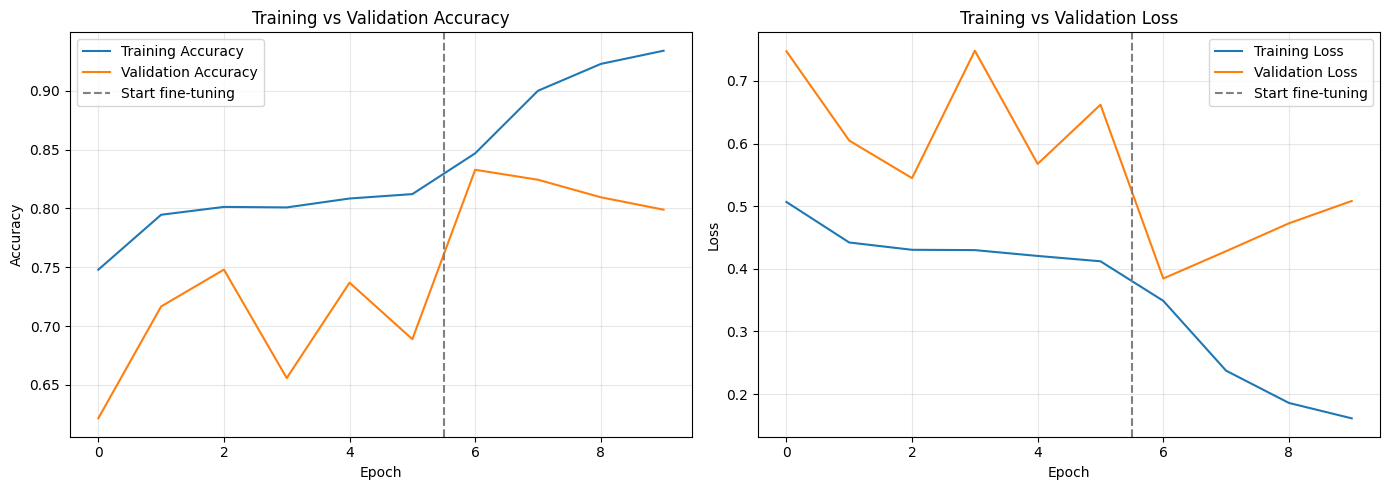

,accuracy,auc,loss,precision,recall,val_accuracy,val_auc,val_loss,val_precision,val_recall,learning_rate,stage
epoch,,,,,,,,,,,,
0,0.747965,0.828963,0.506777,0.935709,0.749022,0.621637,0.881764,0.747349,0.977368,0.558906,0.001000,frozen
1,0.794659,0.875917,0.442076,0.950459,0.795031,0.716700,0.889095,0.604775,0.972673,0.679119,0.001000,frozen
2,0.801347,0.883025,0.430420,0.952952,0.801171,0.748054,0.891874,0.544848,0.970318,0.719680,0.001000,frozen
3,0.800919,0.883775,0.429922,0.952185,0.801342,0.655882,0.889093,0.748213,0.978886,0.600000,0.001000,frozen
4,0.808487,0.889079,0.420607,0.955171,0.808111,0.736936,0.891268,0.567501,0.969087,0.706871,0.000500,frozen
5,0.812223,0.893464,0.412085,0.955408,0.812595,0.688904,0.892122,0.662031,0.977046,0.641761,0.000250,frozen
6,0.846875,0.924963,0.348942,0.966354,0.845695,0.832889,0.934171,0.384597,0.975103,0.820414,0.000010,fine_tune
7,0.900067,0.965568,0.237442,0.980060,0.898358,0.824439,0.944765,0.428217,0.981132,0.804803,0.000010,fine_tune
8,0.922866,0.978838,0.185965,0.986198,0.920320,0.809540,0.951184,0.472679,0.988015,0.780921,0.000005,fine_tune


In [17]:
h1 = pd.DataFrame(history_s1.history); h1["stage"] = "frozen"
h2 = pd.DataFrame(history_s2.history); h2["stage"] = "fine_tune"
history_df = pd.concat([h1, h2], ignore_index=True)
history_df.index.name = "epoch"

HISTORY_PATH = MODEL_DIR / "mobilenetv2_history.csv"
history_df.to_csv(HISTORY_PATH)

split_at = len(h1) - 0.5
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (tr, va, title) in zip(
    axes,
    [("accuracy", "val_accuracy", "Accuracy"), ("loss", "val_loss", "Loss")],
):
    ax.plot(history_df[tr].values, label=f"Training {title}")
    ax.plot(history_df[va].values, label=f"Validation {title}")
    ax.axvline(split_at, color="gray", linestyle="--", label="Start fine-tuning")
    ax.set_title(f"Training vs Validation {title}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(title)
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(MODEL_DIR / "mobilenetv2_training_curves.png", dpi=150)
plt.show()

display(history_df)

## Save Experiment Configuration

In [18]:
best_model = tf.keras.models.load_model(BEST_MODEL_PATH)
model_size_mb = BEST_MODEL_PATH.stat().st_size / (1024 ** 2)

training_config = {
    "experiment": "Model B - MobileNetV2 (transfer learning)",
    "dataset": DATASET_ID,
    "dataset_revision": HF_REVISION,
    "target": "label_a",
    "class_mapping": {"0": "Real", "1": "AI-Generated"},
    "image_size": IMAGE_SIZE,
    "color_mode": "RGB",
    "resize_interpolation": "bilinear",
        "model_specific_preprocessing": "Custom layer MobileNetV2Preprocess inside the model: x/127.5 - 1 -> [-1,1] (same as mobilenet_v2.preprocess_input). The saved model expects raw 0-255 RGB, 224x224.",
    "augmentation_training_only": ["RandomFlip(horizontal)", "RandomZoom(0.1)"],
    "backbone": "MobileNetV2, ImageNet weights, include_top=False",
    "head": f"GlobalAveragePooling2D -> Dropout({best_config['dropout']}) -> Dense(1, sigmoid)",
    "batch_size": BATCH_SIZE,
    "seed": SEED,
    "class_weights": {str(k): float(v) for k, v in class_weights.items()},
    "tuning": {
        "ran": RUN_TUNING,
        "subset_train": TUNE_TRAIN_SIZE, "subset_val": TUNE_VAL_SIZE, "epochs": TUNE_EPOCHS,
        "results": tuning_df.to_dict(orient="records"),
        "selected": best_config,
    },
    "stage1_frozen": {
        "optimizer": "Adam", "learning_rate": best_config["learning_rate"],
        "epochs_requested": STAGE1_EPOCHS, "epochs_completed": len(history_s1.epoch),
    },
    "stage2_finetune": {
        "optimizer": "Adam", "learning_rate": FINE_TUNE_LR,
        "unfrozen_backbone_layers": FINE_TUNE_LAYERS, "batchnorm_frozen": True,
        "epochs_requested": STAGE2_EPOCHS, "epochs_completed": len(history_s2.epoch),
    },
    "validation_results": {k: {m: float(v[m]) for m in v if m != "path"} for k, v in candidates.items()},
    "best_model_stage": best_name,
    "training_samples": len(train_df),
    "validation_samples": len(val_df),
    "model_file": BEST_MODEL_PATH.name,
    "model_size_mb": round(model_size_mb, 2),
    "total_parameters": int(best_model.count_params()),
}

CONFIG_PATH = MODEL_DIR / "mobilenetv2_config.json"
with open(CONFIG_PATH, "w", encoding="utf-8") as f:
    json.dump(training_config, f, indent=4)

if len(tuning_df):
    tuning_df.to_csv(MODEL_DIR / "mobilenetv2_tuning.csv", index=False)

for p in sorted(MODEL_DIR.glob("mobilenetv2_*")):
    print(p.name, f"{p.stat().st_size / (1024**2):.2f} MB")

mobilenetv2_best.keras 20.73 MB
mobilenetv2_config.json 0.00 MB
mobilenetv2_history.csv 0.00 MB
mobilenetv2_stage1_best.keras 9.19 MB
mobilenetv2_stage2_best.keras 20.73 MB
mobilenetv2_training_curves.png 0.11 MB
mobilenetv2_tuning.csv 0.00 MB


In [20]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [21]:
import shutil
from pathlib import Path

DRIVE_DIR = Path("/content/drive/MyDrive/ModelB_backup")
DRIVE_DIR.mkdir(parents=True, exist_ok=True)
for p in MODEL_DIR.glob("mobilenetv2_*"):
    shutil.copy2(p, DRIVE_DIR / p.name)
    print("Backed up:", p.name)

Backed up: mobilenetv2_training_curves.png
Backed up: mobilenetv2_config.json
Backed up: mobilenetv2_stage2_best.keras
Backed up: mobilenetv2_best.keras
Backed up: mobilenetv2_history.csv
Backed up: mobilenetv2_tuning.csv
Backed up: mobilenetv2_stage1_best.keras


In [23]:
import zipfile
from google.colab import files

ZIP_PATH = Path("/content/mobilenetv2_model_b_artifacts.zip")

# Semua file hasil Model B, termasuk checkpoint stage 1 dan stage 2 sebagai cadangan
files_to_zip = sorted(MODEL_DIR.glob("mobilenetv2_*"))
assert files_to_zip, "Tidak ada file mobilenetv2_* di MODEL_DIR. Pastikan training sudah selesai."

with zipfile.ZipFile(ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for fp in files_to_zip:
        zf.write(fp, arcname=fp.name)
        print("Added:", fp.name, f"({fp.stat().st_size / (1024**2):.2f} MB)")

print(f"\nZIP size: {ZIP_PATH.stat().st_size / (1024**2):.2f} MB")

try:
    files.download(str(ZIP_PATH))
    print("Download dimulai. Cek folder Downloads di komputermu.")
except Exception as e:
    print("Download otomatis gagal:", e)
    print("File zip tetap ada di panel Files Colab: /content/mobilenetv2_model_b_artifacts.zip (klik kanan > Download).")

Added: mobilenetv2_best.keras (20.73 MB)
Added: mobilenetv2_config.json (0.00 MB)
Added: mobilenetv2_history.csv (0.00 MB)
Added: mobilenetv2_stage1_best.keras (9.19 MB)
Added: mobilenetv2_stage2_best.keras (20.73 MB)
Added: mobilenetv2_training_curves.png (0.11 MB)
Added: mobilenetv2_tuning.csv (0.00 MB)

ZIP size: 45.64 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download dimulai. Cek folder Downloads di komputermu.
